# Chapter 13: Computational Performance

# 13.1 Compilers and Interpreters
* So far, D2L book has focused on imperative programming which makes use of statements like print, +, if to change a program's state. COnsider the following example below of a simple imperative program

In [1]:
def add(a, b):
    return a + b

def fancy_func(a, b, c, d):
    e = add(a, b)
    f = add(c, d)
    g = add(e, f)
    return g

print(fancy_func(1, 2, 3, 4))

10


* Python is an interpreted langauge
* When evaluating fancy_func functino above, it performs the operations making up the function's body in sequence (serially)
    * it will evaluate e = add(a, b) and store the results as variable e, thus changing the program's state
    * Statements for f = add(c, d) and g = add(e, f) will be executed similarly, performing additions and storing the results as variables
* Although imperative programming is convienent, it may be inefficient because although the add function is repeatedly called throughout the fancy_func function, Python will executive 3 individual function calls - and if executed on GPU, the overhead arising from Python interpreter can become overwhelming. It will also need to save variable values for e and f until the entire fancy_func has finished executing, since we do now know whether variables e and f will be used by other parts of program after e and f statements are executed

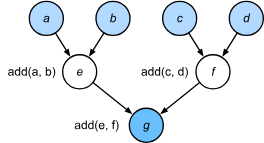

### 13.1.1 Symbolic Programming
* Alternative method, where computation is usually performed only once the process is fully defined
* Strategy is used by multiple deep learning frameworks such as Theano and TensorFlow (latter of which has acquired imperative extensions)
* Symbolic Programming involves following steps:
    1. Define operations to be executed
    1. Compile the operations into an executable program
    1. Provide the required inputs and call the compiled program for execution
* Symbolic allows for significant optimization 
    1. Allows us to skip Python interpreter in many cases, removing performance bottleneck that can become significant on multiple fast GPUs paired with single Python thread on CPU
    1. Compiler might optimize and rewrite the above code into print((1+2) + (3+4)) or even print(10). This is possible because a compiler gets to see the full code ebfore turning it into machine instructions, so it can release memory, or even never allocate it in the first place whenever a variable is no longer needed

* The differences between imperative (interpreted) programming and symbolic programming are as follows:
    * Imperative programming is easier. 
        * When imperative programming is used in Python, the majority of the code is straightforward and easy to write. 
        * It is also easier to debug imperative programming code. This is because it is easier to obtain and print all relevant intermediate variable values, or use Python’s built-in debugging tools.
    * Symbolic programming is more efficient and easier to port. 
        * Symbolic programming makes it easier to optimize the code during compilation, while also having the ability to port the program into a format independent of Python. 
        * This allows the program to be run in a non-Python environment, thus avoiding any potential performance issues related to the Python interpreter.

In [2]:
def add_():
    return '''
def add(a, b):
    return a + b
'''

def fancy_func_():
    return '''
def fancy_func(a, b, c, d):
    e = add(a, b)
    f = add(c, d)
    g = add(e, f)
    return g
'''

def evoke_():
    return add_() + fancy_func_() + 'print(fancy_func(1, 2, 3, 4))'

prog = evoke_()
print(prog)
y = compile(prog, '', 'exec')
exec(y)


def add(a, b):
    return a + b

def fancy_func(a, b, c, d):
    e = add(a, b)
    f = add(c, d)
    g = add(e, f)
    return g
print(fancy_func(1, 2, 3, 4))
10


### 13.1.2 Hybrid Programming

### 13.1.3 Hybridizing the Sequential Class

### 13.1.4 Summary

### 13.1.5 Exercises
1. Review the models that interest you in the previous chapters. Can you improve their computational performance by reimplementing them?

# 13.2 Asynchronous Computation

### 13.2.1 Asynchrony via Backend

### 13.2.2 Barriers and Blockers

### 13.2.3 Improving Computation

### 13.2.4 Summary

### 13.2.5 Exercises
1. On the CPU, benchmark the same matrix multiplication operations in this section. Can you still observe asynchrony via the backend?

# 13.3 Automatic Parallelism

### 13.3.1 Parallel Computation on GPUs

### 13.3.2 Parallel Computation and Communication

### 13.3.3 Summary

### 13.3.4 Exercises
1. Eight operations were performed in the `run` function defined in this section. There are no dependencies between them. Design an experiment to see if the deep learning framework will automatically execute them in parallel.
1. When the workload of an individual operator is sufficiently small, parallelization can help even on a single CPU or GPU. Design an experiment to verify this.
1. Design an experiment that uses parallel computation on CPUs, GPUs, and communication between both devices.
1. Use a debugger such as NVIDIA's [Nsight](https://developer.nvidia.com/nsight-compute-2019_5) to verify that your code is efficient.
1. Designing computation tasks that include more complex data dependencies, and run experiments to see if you can obtain the correct results while improving performance.


# 13.4 Hardware

### 13.4.1 Computers

### 13.4.2 Memory

### 13.4.3 Storage

### 13.4.4 CPUs

### 13.4.5 GPUs and other Accelerators

### 13.4.6 Networks and Buses

### 13.4.7 More Latency Numbers

### 13.4.8 Summary

### 13.4.9 Exercises
1. Write C code to test whether there is any difference in speed between accessing memory aligned or misaligned relative to the external memory interface. Hint: be careful of caching effects.
1. Test the difference in speed between accessing memory in sequence or with a given stride.
1. How could you measure the cache sizes on a CPU?
1. How would you lay out data across multiple memory channels for maximum bandwidth? How would you lay it out if you had many small threads?
1. An enterprise-class HDD is spinning at 10,000 rpm. What is the absolutely minimum time an HDD needs to spend worst case before it can read data (you can assume that heads move almost instantaneously)? Why are 2.5" HDDs becoming popular for commercial servers (relative to 3.5" and 5.25" drives)?
1. Assume that an HDD manufacturer increases the storage density from 1 Tbit per square inch to 5 Tbit per square inch. How much information can you store on a ring on a 2.5" HDD? Is there a difference between the inner and outer tracks?
1. Going from 8 bit to 16 bit data types increases the amount of silicon approximately by four times. Why? Why might NVIDIA have added INT4 operations to their Turing GPUs?
1. How much faster is it to read forward through memory vs. reading backwards? Does this number differ between different computers and CPU vendors? Why? Write C code and experiment with it.
1. Can you measure the cache size of your disk? What is it for a typical HDD? Do SSDs need a cache?
1. Measure the packet overhead when sending messages across the Ethernet. Look up the difference between UDP and TCP/IP connections.
1. Direct memory access allows devices other than the CPU to write (and read) directly to (from) memory. Why is this a good idea?
1. Look at the performance numbers for the Turing T4 GPU. Why does the performance "only" double as you go from FP16 to INT8 and INT4?
1. What is the shortest time it should take for a packet on a round trip between San Francisco and Amsterdam? Hint: you can assume that the distance is 10,000 km.


# 13.5 Training on Multiple GPUs

### 13.5.1 Splitting the Problem

### 13.5.2 Data Parallelism

### 13.5.3 A Toy Network

### 13.5.4 Data Synchronization

### 13.5.5 Distributing Data

### 13.5.6 Training

### 13.5.7 Summary

### 13.5.8 Exercises
1. When training on $k$ GPUs, change the minibatch size from $b$ to $k \cdot b$, i.e., scale it up by the number of GPUs.
1. Compare accuracy for different learning rates. How does it scale with the number of GPUs?
1. Implement a more efficient `allreduce` function that aggregates different parameters on different GPUs? Why is it more efficient?
1. Implement multi-GPU test accuracy computation.

# 13.6 Concise Implementation for Multiple GPUs

### 13.6.1 A Toy Network

### 13.6.2 Network Initialization

### 13.6.3 Training

### 13.6.4 Summary

### 13.6.5 Exercises

1. This section uses ResNet-18. Try different epochs, batch sizes, and learning rates. Use more GPUs for computation. What happens if you try this with 16 GPUs (e.g., on an AWS p2.16xlarge instance)?
1. Sometimes, different devices provide different computing power. We could use the GPUs and the CPU at the same time. How should we divide the work? Is it worth the effort? Why? Why not?

# 13.7 Parameter Servers

### 13.7.1 Data-Parallel Training

### 13.7.2 Ring Synchronization

### 13.7.3 Multi-Machine Training

### 13.7.4 Key–Value Stores

### 13.7.5 Summary

### 13.7.6 Exercises
1. Can you increase the ring synchronization even further? Hint: you can send messages in both directions.
1. Is it possible to allow asynchronous communication (while computation is still ongoing)? How does it affect performance?
1. What if we lost a server during a long-running computation? How can we design a *fault tolerance* mechanism to avoid restarting the computation fully?